**Group 1:** Sultan Akinola Atanda, John Buni, Echezona Oji, Antonio Sainz


# Foundations of Machine Learning: An Introduction to Neural Networks & MLPs
This notebook is a tutorial on **Neural Networks**. It starts with the basic building block, the "neuron," and builds its way up to a more powerful model capable of solving complex problems: the **Multi-Layered Perceptron (MLP)**.

At the end is a workshop on classifying handwritten digits from the MNIST dataset.

You will be asked to compare the Keras, PyTorch and TensorFlow implementations in terms of accuracy and speed.

<br/>
<br/>

### 💡 Additional Reading Material

These other tutorials come from the Course Notebooks Repository:

> In-depth: 
[**Multiclass Classification - A Simple Keras Model (MNIST)**](https://github.com/CSCN8010/CSCN8010/blob/main/dl_class_notebooks/03A_minimal_mnist_keras.ipynb)

> In-depth: 
[**Train and Aave a Simple Keras Model (MNIST)**](https://github.com/CSCN8010/CSCN8010/blob/main/dl_class_notebooks/03D_keras_checkpoints_save_model.ipynb)

> In-depth: 
[**Loading a pre-trained Keras model and classifying digits (MNIST)**](https://github.com/CSCN8010/CSCN8010/blob/main/dl_class_notebooks/03B_load_minimal_mnist_model.ipynb)  

<br/>
<br/>

***



### 1. The Inspiration: From Biological to Artificial Neurons

At its core, the field of neural networks is inspired by the human brain. We'll start by understanding the basic concept of a neuron.

#### **Key Concepts: The Neuron**

- An artificial intelligence (AI) system is designed to perceive its environment and act accordingly. 
- Neural networks are the "brain" of these systems.
- The simplest neural network is a **perceptron**, which consists of a single artificial neuron.
- The concept of an artificial neuron is modeled after a biological one.

* A **biological neuron** receives electrical signals through its *dendrites*. If the combined strength of these signals surpasses a certain threshold, the neuron "fires," sending an output signal through its *synapses* to other neurons.
* An **artificial neuron** works similarly. It receives multiple *inputs*, performs a calculation, and if the result exceeds a threshold, it produces an *output*.



### 2. The Perceptron: A Single Neuron in Action

Let's break down the mechanics of that single artificial neuron, the perceptron.

#### **Presentation: Anatomy of a Perceptron**

A perceptron operates on a simple principle: it takes a set of inputs, weighs them based on their importance, sums them up, and then uses an **activation function** to decide whether to "fire" and produce an output.

Here are the key components:

1.  **Inputs ($x$)**: These are the features of your data. For example, if you're predicting a house price, inputs could be the size, number of rooms, and age of the house. Each input is a feature that contributes to the final decision.

2.  **Weights ($w$)**: Not all inputs are equally important. Each input feature ($x_i$) is assigned a weight ($w_i$) that reflects its importance in the decision-making process. A higher weight amplifies an input's effect, while a lower weight diminishes it. The network learns these weights during training.

3.  **Weighted Sum ($z$)**: The neuron calculates the sum of all inputs multiplied by their corresponding weights. We also add a **bias ($b$)**, which is like the y-intercept in a linear equation. It allows us to shift the activation function, giving the model more flexibility. The formula is:
    $$z = (x_1w_1 + x_2w_2 + ... + x_nw_n) + b = \sum_{i=1}^{n} x_i w_i + b$$

4.  **Activation Function ($f(z)$)**: This is the decision-making unit of the neuron. It takes the weighted sum ($z$) as input and transforms it into the final output. For a simple step function, the output is either 0 or 1. This introduces non-linearity, which is crucial for learning complex patterns.



#### **Building a Perceptron with Python**

Let's build a simple perceptron from scratch using NumPy to see these concepts in code. We'll use a simple "step" activation function.


In [7]:
import numpy as np

# A simple perceptron class
class Perceptron:
    """A single neuron model."""

    def __init__(self, num_inputs):
        """
        Initializes the perceptron.
        Args:
            num_inputs (int): The number of input features.
        """
        # Initialize weights with small random numbers. Bias is the last weight.
        self.weights = np.random.rand(num_inputs + 1)
        print(f"Initialized weights: {self.weights}")

    def step_function(self, z):
        """The activation function."""
        return 1 if z >= 0 else 0

    def predict(self, inputs):
        """
        Calculates the weighted sum and passes it to the activation function.
        Args:
            inputs (list or np.array): The input features.
        Returns:
            int: The binary output (0 or 1).
        """
        # Add the bias input (always 1)
        inputs_with_bias = np.append(inputs, 1)

        # Calculate the weighted sum: z = sum(x_i * w_i)
        z = np.dot(inputs_with_bias, self.weights)
        print(f"Inputs (with bias): {inputs_with_bias}")
        print(f"Weighted Sum (z): {z:.4f}")

        # Apply the activation function
        output = self.step_function(z)
        print(f"Output: {output}")
        return output

# --- Let's test our Perceptron! ---
# Create a perceptron that takes 2 inputs
p = Perceptron(num_inputs=2)

# Define some sample inputs
sample_inputs = np.array([0.8, 0.5])

# Make a prediction
prediction = p.predict(sample_inputs)
print(f"\nFinal prediction for inputs {sample_inputs} is: {prediction}")


Initialized weights: [0.8759425  0.0748305  0.52202346]
Inputs (with bias): [0.8 0.5 1. ]
Weighted Sum (z): 1.2602
Output: 1

Final prediction for inputs [0.8 0.5] is: 1



### 3. Activation Functions: Adding Non-Linearity

[cite_start]A single perceptron with a step function can only separate data with a single straight line[cite: 178]. To learn truly complex patterns, like those in images or speech, we need more sophisticated activation functions that introduce **non-linearity**.

#### **Presentation: Common Activation Functions**

While there are many activation functions, three are particularly common and important to know. [cite_start]The PDF specifically mentions **ReLU** and **softmax** as popular choices[cite: 280].

1.  **Sigmoid (or Logistic)**
    * **Formula**: $\sigma(z) = \frac{1}{1 + e^{-z}}$
    * **Output Range**: (0, 1)
    * **Use Case**: Excellent for binary classification problems where the output needs to be a probability.
    * **Downside**: Suffers from the "vanishing gradient" problem, which can slow down learning in deep networks.

2.  **Tanh (Hyperbolic Tangent)**
    * **Formula**: $\tanh(z) = \frac{e^z - e^{-z}}{e^z + e^{-z}}$
    * **Output Range**: (-1, 1)
    * **Use Case**: Similar to sigmoid but is "zero-centered," which can sometimes help models learn faster.
    * **Downside**: Also suffers from the vanishing gradient problem.

3.  **ReLU (Rectified Linear Unit)**
    * **Formula**: $R(z) = \max(0, z)$
    * **Output Range**: [0, $\infty$)
    * **Use Case**: The most popular activation function for hidden layers in deep learning. It's computationally very efficient and helps mitigate the vanishing gradient problem.
    * **Downside**: Can "die" if a neuron's output consistently becomes zero, preventing weight updates.



#### **Visualizing Activation Functions**

Let's plot these functions to understand their behavior.


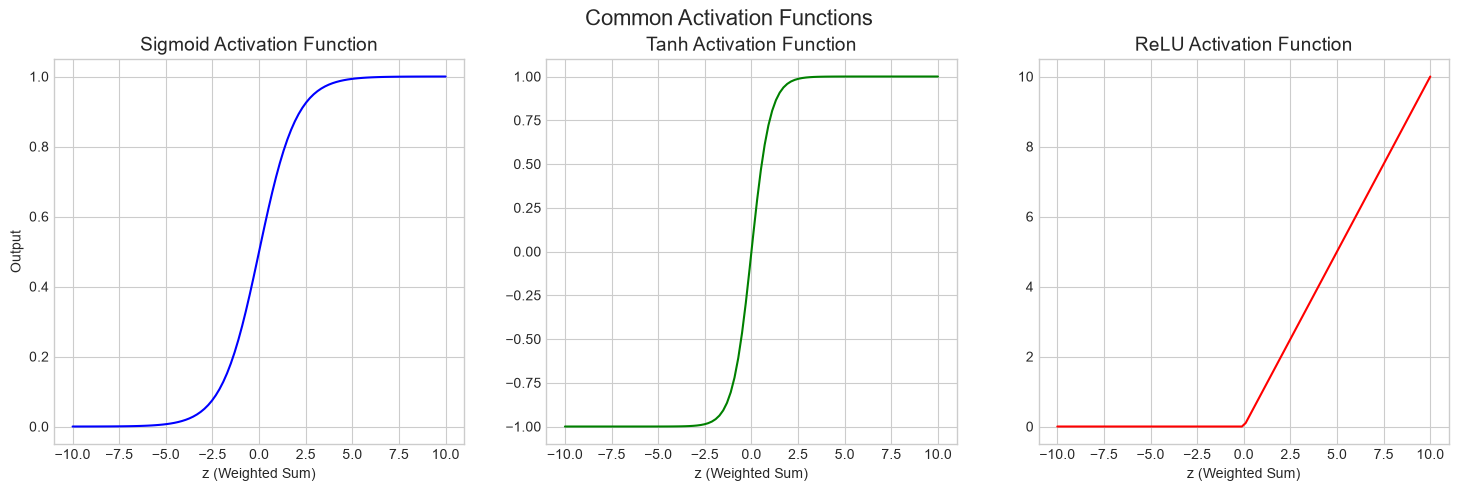

In [8]:
import numpy as np
import matplotlib.pyplot as plt

# Define the input range
z = np.linspace(-10, 10, 100)

# Define the activation functions
def sigmoid(x):
    return 1 / (1 + np.exp(-x))

def tanh(x):
    return np.tanh(x)

def relu(x):
    return np.maximum(0, x)

# Plotting
plt.style.use('seaborn-v0_8-whitegrid')
fig, axs = plt.subplots(1, 3, figsize=(18, 5))

axs[0].plot(z, sigmoid(z), color='blue')
axs[0].set_title('Sigmoid Activation Function', fontsize=14)
axs[0].set_xlabel('z (Weighted Sum)')
axs[0].set_ylabel('Output')

axs[1].plot(z, tanh(z), color='green')
axs[1].set_title('Tanh Activation Function', fontsize=14)
axs[1].set_xlabel('z (Weighted Sum)')

axs[2].plot(z, relu(z), color='red')
axs[2].set_title('ReLU Activation Function', fontsize=14)
axs[2].set_xlabel('z (Weighted Sum)')

plt.suptitle('Common Activation Functions', fontsize=16)
plt.show()



### 4. From One to Many: The Multi-Layer Perceptron (MLP)

A single neuron is limited. To solve complex, **non-linear problems**, we need to combine many neurons into a network.

#### **MLP Architecture**

A very common architecture is to stack neurons in layers. This creates a **Multi-Layer Perceptron (MLP)**. An MLP has three types of layers:

1.  **Input Layer**: This layer receives the initial feature vector. It doesn't perform calculations; it simply passes the data to the first hidden layer.
2.  **Hidden Layers**: These are the layers between the input and output. This is where most of the learning happens. Each neuron in a hidden layer receives outputs from the previous layer, performs the `weighted sum -> activation` calculation, and passes its output to the next layer. Networks with two or more hidden layers are often called **deep neural networks**.
3.  **Output Layer**: This is the final layer that produces the model's prediction. The number of neurons and the activation function in this layer depend on the problem you're solving (e.g., one neuron with a sigmoid for binary classification, or multiple neurons with a softmax function for multi-class classification).

In an MLP, layers are typically **fully connected**, meaning every neuron in one layer is connected to every neuron in the next layer.



### 5. The Learning Process: Feedforward & Backpropagation

How does an MLP actually *learn*? It's a two-part process that is repeated many times: **Feedforward** to make a prediction, and **Backpropagation** to correct errors.

#### **The Learning Loop**

**Step 1: Feedforward (Making a Prediction)**

This is the process of information flowing forward through the network.

1.  The input data is fed into the **input layer**.
2.  The data flows to the first **hidden layer**. Each neuron in this layer calculates its weighted sum and applies its activation function.
3.  The outputs of the first hidden layer become the inputs for the second hidden layer, and so on.
4.  This continues until the data reaches the **output layer**, which produces the final prediction ($y'$).

The entire process is a chain of `weighted sum -> activation` calculations, layer by layer, from input to output.

**Step 2: Backpropagation (Learning from Mistakes)**

Once the network makes a prediction ($y'$), we need to see how good it was.

1.  **Compute Error (Loss)**: We compare the network's prediction ($y'$) with the correct, true label ($y$). The difference is the **error**. We use an **error function** (or loss function) like Mean Squared Error or Cross-Entropy to calculate a single score representing how wrong the model was.
    * **Error Calculation**: `error = y - y'` 

2.  **Propagate Error Backwards**: This is the magic of backpropagation. The error is sent backward through the network, from the output layer to the input layer.

3.  **Update Weights**: As the error propagates back, it's used to calculate how much each weight and bias in the network contributed to the total error. The network then adjusts its weights to reduce the error. For instance, if a large weight led to a large error, the network will decrease that weight. This process uses calculus (specifically, an algorithm called **gradient descent**) to find the optimal weight values that minimize the error. For a more in-depth analysis of this method, read the tutorial at [3Blue1Brown - What is Backpropagation Really Doing?](https://www.3blue1brown.com/lessons/backpropagation)

4.  **Repeat**: This entire `feedforward -> backpropagation` cycle is repeated many times (for many **epochs**) with the entire training dataset. With each cycle, the network's weights get a little bit better, and its predictions become more and more accurate.


## 🔄 Understanding How the Model Compares Predictions to True Labels (Backpropagation Step 2)

During training, your model learns by comparing its **predicted output** to the **correct, true label** that comes from the dataset. This comparison happens **during every epoch**, and it is essential for calculating the **loss** (error), which drives backpropagation.

### ✅ What Happens During Training (Simplified View)

1. **Training Dataset**  
   You start with a dataset consisting of input–output pairs:  
   $$
   (X, y) = \\{(x^{(1)}, y^{(1)}), (x^{(2)}, y^{(2)}), ..., (x^{(n)}, y^{(n)})\\}
   $$
   - $x^{(i)}$ is the input vector (features)
   - $y^{(i)}$ is the correct, true label (target output)

2. **Model Initialization**  
   The model starts with **random weights**.

3. **Epoch Loop**  
   For each epoch:
   - For each mini-batch or training sample:
     1. Feed **input `x`** into the model → get prediction `y_pred`
     2. Compare `y_pred` with the **true label `y_true`**
     3. Compute **loss** using a loss function (e.g., MSE or Cross-Entropy)
     4. Perform **backpropagation** to compute gradients
     5. **Update weights** with an optimizer

### 🧠 Pseudocode: Training Up to Loss Calculation

```python
# Assume: training_data = [(x1, y1), (x2, y2), ..., (xn, yn)]
# x = input vector, y = true label

initialize_model_weights()

for epoch in range(num_epochs):
    for x, y_true in training_data:
        
        # ---- FEEDFORWARD ----
        y_pred = model.forward(x)  # Predict output based on current weights
        
        # ---- COMPARE PREDICTION TO TRUE LABEL ----
        # Step 1: Compute loss (error between prediction and true label)
        loss = loss_function(y_pred, y_true)  # e.g., MSE, Cross-Entropy

        # ---- BACKPROPAGATION ----
        gradients = compute_gradients(loss, model.weights)
        
        # ---- UPDATE WEIGHTS ----
        optimizer.step(model.weights, gradients)
````

### 💬 Where Does `y_true` Come From?

It comes from the **training dataset**, which:

* Is usually prepared as `(X_train, y_train)` arrays
* Or loaded using a **DataLoader** that returns `(x, y)` pairs

During training, for every training example or batch:

* The model uses the **input `x`** to make a prediction
* The **label `y_true`** is passed into the **loss function** to compute how wrong the prediction was


### 🎓 Example (PyTorch Training Loop)

```python
for x_batch, y_true in train_loader:
    y_pred = model(x_batch)                  # Forward pass
    loss = loss_fn(y_pred, y_true)           # Compare prediction to true label
    loss.backward()                          # Backpropagation
    optimizer.step()                         # Update weights
    optimizer.zero_grad()                    # Reset gradients
```

### 📝 To summarize...

* The **true label `y_true`** comes from the training dataset.
* It is compared to the **model’s prediction `y_pred`** inside the loss function.
* The result (error/loss) is backpropagated to update weights and improve predictions.




### 6. Building an MLP: The Complete Workshop

Now, let's put it all together. We will build, train, and evaluate an MLP to solve a classic machine learning problem: classifying handwritten digits from the MNIST dataset. We'll use the three most popular deep learning libraries: **Keras (with a TensorFlow backend)**, **TensorFlow (Core API)**, and **PyTorch**.

This will show you that while the syntax differs, the core concepts�defining layers, choosing a loss function, and training the model�are universal.

#### **Code Workshop: MNIST Digit Classification**

First, let's load and prepare our data.


In [9]:
import tensorflow as tf
from tensorflow import keras
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms
import numpy as np
import matplotlib.pyplot as plt

# --- Load and Preprocess Data ---
# Load data for TensorFlow/Keras
(x_train_tf, y_train_tf), (x_test_tf, y_test_tf) = keras.datasets.mnist.load_data()

# Normalize pixel values to be between 0 and 1
x_train_tf = x_train_tf.astype("float32") / 255.0
x_test_tf = x_test_tf.astype("float32") / 255.0

# Flatten the images from 28x28 to 784-element vectors
x_train_flat = x_train_tf.reshape(-1, 784)
x_test_flat = x_test_tf.reshape(-1, 784)

print(f"TensorFlow/Keras Data Shape: {x_train_flat.shape}")

# Load data for PyTorch
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

train_dataset_pt = datasets.MNIST(root='./data', train=True, download=True, transform=transform)
test_dataset_pt = datasets.MNIST(root='./data', train=False, download=True, transform=transform)

train_loader_pt = torch.utils.data.DataLoader(train_dataset_pt, batch_size=64, shuffle=True)
test_loader_pt = torch.utils.data.DataLoader(test_dataset_pt, batch_size=64, shuffle=False)

print(f"PyTorch Data Loaded. Number of training batches: {len(train_loader_pt)}")


TensorFlow/Keras Data Shape: (60000, 784)
PyTorch Data Loaded. Number of training batches: 938



#### **Implementation 1: Keras**

Keras is popular due to its simplicity and user-friendly API. 

> Note the time spent training the model. 

- Tweak the hyperparameters to and test their impact on training speed.
- Analyze the training metrics (on the output). What are `val_accuracy` and `val_loss` ?


In [10]:

# --- 1. Define the Keras Model ---
# This is a sequential model, a simple stack of layers.
model_keras = keras.Sequential([
    # Input layer: 784 inputs (our flattened 28x28 image)
    keras.layers.Input(shape=(784,)),
    # Hidden Layer 1: 128 neurons, ReLU activation
    keras.layers.Dense(128, activation='relu'),
    # Hidden Layer 2: 64 neurons, ReLU activation
    keras.layers.Dense(64, activation='relu'),
    # Output Layer: 10 neurons (for digits 0-9), softmax for multi-class probability
    keras.layers.Dense(10, activation='softmax')
])

# Print a summary of the model architecture
model_keras.summary()

# --- 2. Compile the Model ---
# This step configures the model for training.
model_keras.compile(
    optimizer='adam',  # Adam is an efficient optimization algorithm
    loss='sparse_categorical_crossentropy',  # A common loss function for multi-class classification
    metrics=['accuracy']  # We want to monitor the accuracy
)

# --- 3. Train the Model ---
print("\n--- Training Keras Model ---")
history = model_keras.fit(
    x_train_flat,
    y_train_tf,
    batch_size=64,
    epochs=5,  # An epoch is one full pass through the entire training dataset
    validation_split=0.1 # Use 10% of training data for validation
)

# --- 4. Evaluate the Model ---
print("\n--- Evaluating Keras Model ---")
test_loss, test_acc = model_keras.evaluate(x_test_flat, y_test_tf, verbose=2)
print(f"\nKeras Test Accuracy: {test_acc:.4f}")


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_6 (Dense)                 │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)


--- Training Keras Model ---
Epoch 1/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 36s 41ms/step - accuracy: 0.9131 - loss: 0.3002 - val_accuracy: 0.9657 - val_loss: 0.1246
Epoch 2/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 16s 19ms/step - accuracy: 0.9627 - loss: 0.1245 - val_accuracy: 0.9717 - val_loss: 0.1014
Epoch 3/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 19s 15ms/step - accuracy: 0.9749 - loss: 0.0848 - val_accuracy: 0.9758 - val_loss: 0.0889
Epoch 4/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 34s 28ms/step - accuracy: 0.9817 - loss: 0.0613 - val_accuracy: 0.9762 - val_loss: 0.0885
Epoch 5/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 30s 14ms/step - accuracy: 0.9864 - loss: 0.0460 - val_accuracy: 0.9745 - val_loss: 0.0956

--- Evaluating Keras Model ---
313/313 - 1s - 3ms/step - accuracy: 0.9722 - loss: 0.0925

Keras Test Accuracy: 0.9722


#### Keras – Answers

`val_accuracy` and `val_loss` are the accuracy and loss on the **validation set**. Because of `validation_split=0.1`, Keras keeps 6,000 training images aside and never trains on them. After every epoch it tests the model on those images.

- `accuracy` and `loss` show how well the model does on images it has already seen.
- `val_accuracy` and `val_loss` show how it does on images it hasn't seen.

In our run, `val_loss` was lowest at epoch 4 (0.0885) and then rose to 0.0956 at epoch 5, while the training loss kept falling (0.0613 → 0.0460). The model was starting to memorise the training images, which is early overfitting. Four epochs would have been enough.


#### **Implementation 2: PyTorch**

PyTorch is known for its flexibility and is very popular in research. The structure is more explicit, requiring you to define the model as a class. 

> Note the time spent training the model. 

- Tweak the hyperparameters to and test their impact on training speed.
- Analyze the code. What are `images`, `labels`, `criterion` and `optimizer` ?


In [11]:

# --- 1. Define the PyTorch Model ---
class MLP_PyTorch(nn.Module):
    def __init__(self):
        super(MLP_PyTorch, self).__init__()
        self.flatten = nn.Flatten()
        # Define the sequence of layers
        self.layers = nn.Sequential(
            nn.Linear(28 * 28, 128), # Input -> Hidden 1
            nn.ReLU(),
            nn.Linear(128, 64),      # Hidden 1 -> Hidden 2
            nn.ReLU(),
            nn.Linear(64, 10)        # Hidden 2 -> Output
        )

    def forward(self, x):
        # This defines the feedforward pass
        x = self.flatten(x)
        logits = self.layers(x)
        return logits

model_pt = MLP_PyTorch()
print(model_pt)

# --- 2. Define Loss and Optimizer ---
criterion = nn.CrossEntropyLoss() # Combines LogSoftmax and NLLLoss
optimizer = optim.Adam(model_pt.parameters(), lr=0.001)

# --- 3. Train the Model ---
print("\n--- Training PyTorch Model ---")
model_pt.train() # Set the model to training mode
for epoch in range(5):
    running_loss = 0.0
    for i, (images, labels) in enumerate(train_loader_pt):
        # Zero the parameter gradients
        optimizer.zero_grad()

        # Forward pass
        outputs = model_pt(images)
        loss = criterion(outputs, labels)

        # Backward pass and optimize
        loss.backward()
        optimizer.step()

        running_loss += loss.item()
    print(f"Epoch {epoch+1}, Loss: {running_loss/len(train_loader_pt):.4f}")

# --- 4. Evaluate the Model ---
print("\n--- Evaluating PyTorch Model ---")
model_pt.eval() # Set the model to evaluation mode
correct = 0
total = 0
with torch.no_grad(): # We don't need to calculate gradients during evaluation
    for images, labels in test_loader_pt:
        outputs = model_pt(images)
        _, predicted = torch.max(outputs.data, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

print(f"PyTorch Test Accuracy: {correct / total:.4f}")


MLP_PyTorch(
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (layers): Sequential(
    (0): Linear(in_features=784, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=64, bias=True)
    (3): ReLU()
    (4): Linear(in_features=64, out_features=10, bias=True)
  )
)

--- Training PyTorch Model ---
Epoch 1, Loss: 0.3918
Epoch 2, Loss: 0.1789
Epoch 3, Loss: 0.1317
Epoch 4, Loss: 0.1082
Epoch 5, Loss: 0.0924

--- Evaluating PyTorch Model ---
PyTorch Test Accuracy: 0.9633


#### PyTorch – Answers

- `images`: one batch of 64 pictures with shape `[64, 1, 28, 28]`. The transform scales the pixels to between -1 and 1.
- `labels`: the correct digit (0–9) for each picture in the batch. The predictions are compared against these.
- `criterion`: the loss function, `CrossEntropyLoss`. It applies softmax itself, which is why the model's last layer has no softmax.
- `optimizer`: Adam with learning rate 0.001. `loss.backward()` works out the gradients and `optimizer.step()` uses them to change the weights. `zero_grad()` clears the old gradients first, because PyTorch adds them up otherwise.

PyTorch was the slowest of the three (5 min 17 s). Most of that time goes into the data loader, which converts and normalises every image one at a time, every epoch.


#### **Implementation 3: TensorFlow (Core API)**

This shows how to build a model using the core TensorFlow 2.x API, which is more verbose than Keras but offers more control.

> Note the time spent training the model. 

- Tweak the hyperparameters to and test their impact on training speed.
- Analyze the training metrics (on the output). What are `@tf.function`, `loss_object` and `optimizer_tf` ?


In [12]:

# Using the data we already loaded and flattened for Keras
# Create TensorFlow datasets
train_dataset_tf = tf.data.Dataset.from_tensor_slices((x_train_flat, y_train_tf)).shuffle(60000).batch(64)
test_dataset_tf = tf.data.Dataset.from_tensor_slices((x_test_flat, y_test_tf)).batch(64)

# --- 1. Define the TensorFlow Model ---
class MLP_TensorFlow(tf.keras.Model):
    def __init__(self):
        super(MLP_TensorFlow, self).__init__()
        self.dense1 = tf.keras.layers.Dense(128, activation='relu')
        self.dense2 = tf.keras.layers.Dense(64, activation='relu')
        self.dense3 = tf.keras.layers.Dense(10) # Logits output, softmax is in the loss

    def call(self, x):
        x = self.dense1(x)
        x = self.dense2(x)
        return self.dense3(x)

model_tf = MLP_TensorFlow()

# --- 2. Define Loss and Optimizer ---
loss_object = tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True)
optimizer_tf = tf.keras.optimizers.Adam()

# --- 3. Define Training and Test Steps (more explicit than Keras) ---
#  @tf.function is a decorator. It converts regular Python code into an optimized TensorFlow graph
@tf.function
def train_step(images, labels):
    with tf.GradientTape() as tape:
        predictions = model_tf(images, training=True)
        loss = loss_object(labels, predictions)
    gradients = tape.gradient(loss, model_tf.trainable_variables)
    optimizer_tf.apply_gradients(zip(gradients, model_tf.trainable_variables))
    return loss

# --- 4. Train the Model ---
print("\n--- Training TensorFlow Core API Model ---")
for epoch in range(5):
    epoch_loss_avg = tf.keras.metrics.Mean()
    for images, labels in train_dataset_tf:
        loss = train_step(images, labels)
        epoch_loss_avg.update_state(loss)
    print(f"Epoch {epoch+1}, Loss: {epoch_loss_avg.result():.4f}")

# --- 5. Evaluate the Model ---
print("\n--- Evaluating TensorFlow Core API Model ---")
accuracy_metric = tf.keras.metrics.SparseCategoricalAccuracy()
for images, labels in test_dataset_tf:
    predictions = model_tf(images, training=False)
    accuracy_metric.update_state(labels, predictions)

print(f"TensorFlow Core Test Accuracy: {accuracy_metric.result():.4f}")



--- Training TensorFlow Core API Model ---
Epoch 1, Loss: 0.2711
Epoch 2, Loss: 0.1101
Epoch 3, Loss: 0.0751
Epoch 4, Loss: 0.0583
Epoch 5, Loss: 0.0450

--- Evaluating TensorFlow Core API Model ---
TensorFlow Core Test Accuracy: 0.9776


In [13]:
import time


def time_one_epoch(use_graph):
    model = MLP_TensorFlow()
    opt = tf.keras.optimizers.Adam()

    def step(x, y):
        with tf.GradientTape() as tape:
            loss = loss_object(y, model(x, training=True))
        grads = tape.gradient(loss, model.trainable_variables)
        opt.apply_gradients(zip(grads, model.trainable_variables))

    if use_graph:
        step = tf.function(step)
    start = time.perf_counter()
    for x, y in train_dataset_tf:
        step(x, y)
    return time.perf_counter() - start


graph_time = time_one_epoch(use_graph=True)
eager_time = time_one_epoch(use_graph=False)
print(f"With @tf.function: {graph_time:.1f} s")
print(f"Without it:        {eager_time:.1f} s  ({eager_time / graph_time:.1f}x slower)")

With @tf.function: 6.8 s
Without it:        93.7 s  (13.7x slower)


#### TensorFlow Core – Answers

- `@tf.function` turns `train_step` into a TensorFlow graph. The first call is slow while TensorFlow traces the function. After that, each step runs as compiled code instead of line-by-line Python.
- `loss_object` is `SparseCategoricalCrossentropy(from_logits=True)`. "Sparse" means the labels are plain numbers from 0 to 9. `from_logits=True` means the last layer gives raw scores and the loss applies softmax itself.
- `optimizer_tf` is Adam with learning rate 0.001. It takes the gradients from `GradientTape` and updates the weights.

The cell above trains one epoch with and without `@tf.function`. With it, the epoch took 6.8 s. Without it, the same epoch took 93.7 s, about 14 times slower. This is the main reason TensorFlow Core was the fastest.

## 🧠 Challenge 1: Compare the Keras, PyTorch and TensorFlow implementations in terms of accuracy and speed.

Answer the questions posted before each impementation, and use them to produce a table that reveals the differences between the three implementations:

| Framework | Speed | Accuracy | Pros | Cons |
|----------------|-------------|-------------|-------------|-------------|
| Keras | 2m 17s (5 epochs) | 97.22 % | Least code (`compile` → `fit` → `evaluate`); built-in validation split, accuracy tracking and progress bar; best for quick prototyping | Training loop is hidden, so there is less control; harder to customise or debug what happens inside `fit` |
| PyTorch | 5m 17s (5 epochs) | 96.33 % | Explicit, Pythonic code that is easy to debug line by line; full control of the training loop; standard choice in research | Most boilerplate (manual loop, `zero_grad`, evaluation and accuracy code); no built-in validation; torchvision transforms process one image at a time, which slows training on CPU |
| TensorFlow | 1m 27s (5 epochs) | 97.76 % | `@tf.function` compiles each step into a fast graph; fine control with `GradientTape`; same ecosystem as Keras for deployment | Most verbose; first call is slow while the graph is traced; accuracy and validation have to be written by hand |

Then use the table to prepare talking points on:
- Which implementation you prefer to use for classifying digits in the MNINST data set, and why?

<br/>
<br/>
<br/>

### Challenge 1 – Batch Size Test

To test the hyperparameters, we trained all three frameworks again with batch sizes of 32, 64, 128 and 256 (2 epochs each, same network) and timed the training.

In [14]:
import pandas as pd
import plotly.express as px


class BatchSizeTest:
    def __init__(self, batch_sizes=(32, 64, 128, 256), epochs=2):
        self.batch_sizes = batch_sizes
        self.epochs = epochs
        self.rows = []

    def _log(self, framework, batch_size, seconds, acc):
        self.rows.append({"Framework": framework, "Batch size": batch_size,
                          "Train time (s)": round(seconds, 1), "Test accuracy": round(float(acc), 4)})

    def keras(self, batch_size):
        model = keras.Sequential([
            keras.layers.Input(shape=(784,)),
            keras.layers.Dense(128, activation="relu"),
            keras.layers.Dense(64, activation="relu"),
            keras.layers.Dense(10, activation="softmax"),
        ])
        model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
        start = time.perf_counter()
        model.fit(x_train_flat, y_train_tf, batch_size=batch_size, epochs=self.epochs, verbose=0)
        seconds = time.perf_counter() - start
        _, acc = model.evaluate(x_test_flat, y_test_tf, verbose=0)
        self._log("Keras", batch_size, seconds, acc)

    def pytorch(self, batch_size):
        model = MLP_PyTorch()
        loss_fn = nn.CrossEntropyLoss()
        opt = optim.Adam(model.parameters(), lr=0.001)
        loader = torch.utils.data.DataLoader(train_dataset_pt, batch_size=batch_size, shuffle=True)
        model.train()
        start = time.perf_counter()
        for _ in range(self.epochs):
            for images, labels in loader:
                opt.zero_grad()
                loss_fn(model(images), labels).backward()
                opt.step()
        seconds = time.perf_counter() - start
        model.eval()
        hits = 0
        with torch.no_grad():
            for images, labels in test_loader_pt:
                hits += (model(images).argmax(1) == labels).sum().item()
        self._log("PyTorch", batch_size, seconds, hits / len(test_dataset_pt))

    def tensorflow(self, batch_size):
        model = MLP_TensorFlow()
        opt = tf.keras.optimizers.Adam()
        dataset = tf.data.Dataset.from_tensor_slices((x_train_flat, y_train_tf)).shuffle(60000).batch(batch_size)

        @tf.function
        def step(x, y):
            with tf.GradientTape() as tape:
                loss = loss_object(y, model(x, training=True))
            grads = tape.gradient(loss, model.trainable_variables)
            opt.apply_gradients(zip(grads, model.trainable_variables))

        start = time.perf_counter()
        for _ in range(self.epochs):
            for x, y in dataset:
                step(x, y)
        seconds = time.perf_counter() - start
        acc = np.mean(tf.argmax(model(x_test_flat), axis=1).numpy() == y_test_tf)
        self._log("TensorFlow", batch_size, seconds, acc)

    def run(self):
        for bs in self.batch_sizes:
            self.keras(bs)
            self.pytorch(bs)
            self.tensorflow(bs)
        return pd.DataFrame(self.rows)


sweep = BatchSizeTest().run()
sweep

,Framework,Batch size,Train time (s),Test accuracy
0,Keras,32,12.7,0.9702
1,PyTorch,32,108.8,0.9543
2,TensorFlow,32,19.4,0.9723
3,Keras,64,16.3,0.9679
4,PyTorch,64,38.0,0.9550
5,TensorFlow,64,6.2,0.9690
6,Keras,128,4.9,0.9655
7,PyTorch,128,34.7,0.9473
8,TensorFlow,128,4.0,0.9667
9,Keras,256,3.2,0.9587


In [15]:
fig = px.line(sweep, x="Batch size", y="Train time (s)", color="Framework", markers=True,
              color_discrete_map={"Keras": "#D62828", "PyTorch": "#F77F00", "TensorFlow": "#003049"},
              title="Training time vs batch size (2 epochs)", template="plotly_white")
fig.update_traces(line=dict(width=3), marker=dict(size=9))
fig.update_xaxes(type="log", tickvals=[32, 64, 128, 256])
fig.update_layout(height=450)
fig.show()

**What we saw**
- Keras and TensorFlow got much faster as the batch size grew: TensorFlow went from 19.4 s at batch size 32 to 2.9 s at 256, and Keras from 12.7 s to 3.2 s. At batch size 256 there are only 235 steps per epoch instead of 1,875, so there is much less overhead. (Keras at 64 was slower than at 32. Timings on our laptop jumped around between runs, so we read the overall trend rather than single values.)
- PyTorch dropped from 108.8 s at batch size 32 to about 38 s at 64, but then stayed at around 35 s. Beyond that point its time goes into preparing the images one at a time, so bigger batches don't help.
- Accuracy dropped as the batch size grew (Keras 97.02% → 95.87%, PyTorch 95.43% → 92.17%, TensorFlow 97.23% → 96.04%). With the same 2 epochs, bigger batches mean fewer weight updates.

### Challenge 1 – Talking Points: Which One We Prefer for MNIST

We would use **Keras**.

- **Accuracy is about the same.** TensorFlow 97.76%, Keras 97.22%, PyTorch 96.33%. All three train the same network, so a gap of about 1% is mostly random variation. Keras even trained on 6,000 fewer images.
- **Speed:** TensorFlow Core was fastest (1 min 27 s), then Keras (2 min 17 s), then PyTorch (5 min 17 s). Keras was slower partly because it also checks the validation set every epoch. In the batch size test, the gap between Keras and TensorFlow almost disappeared at larger batches (3.2 s vs 2.9 s at batch size 256), which makes sense because Keras runs on TensorFlow.
- **It needs the least code.** `compile`, `fit` and `evaluate` replace the training and test loops we wrote by hand for the other two. We also got `val_loss` for free, which is how we spotted the overfitting after epoch 4.
- **When we'd pick something else:** PyTorch for research or unusual models where we need full control, and TensorFlow Core when we need a custom training step or the fastest training.

### Reflection 1: Comparing the Frameworks

We expected the three frameworks to give different results, but they didn't. All three reached about 97% because they run the same maths. What changed was speed, and the speed came down to how each one runs the code and loads the data.

TensorFlow Core was fastest because `@tf.function` compiles each training step. Running the same step without it was about 14 times slower. PyTorch was slowest, and the batch size test showed why: after batch size 64 its time hardly changed, because it was busy preparing images, not training. Keras sat in between, and at larger batches it was almost as fast as TensorFlow Core.

We also learned that timings on a laptop are not very reliable. Keras took 1 min 6 s in our first run and 2 min 17 s in the second, with the same code. Our lesson is to repeat timing tests and look at the overall trend before deciding which framework is faster. For a standard problem like MNIST, the simplest tool (Keras) is still the right choice for us.

## 🧠 Challenge 2: Forward & Backpropagation in Multi-Layer Networks

### 🎯 **Objective**

In this challenge, you’ll implement and visualize **forward** and **backward propagation** in a **multi-layer neural network** from scratch — without using high-level deep learning libraries (like TensorFlow’s `Keras` or PyTorch’s `nn.Module`).

You’ll deepen your understanding of how **information flows forward** to make predictions and **errors flow backward** to update weights in deep networks.

### 📚 **Background**

In a deep neural network, each layer transforms its inputs through:

1. A **linear transformation** using weights and biases
2. A **non-linear activation** function

Forward propagation computes the output step-by-step through all layers, while backpropagation uses the **chain rule of calculus** to efficiently compute gradients layer by layer in reverse order.

### 🧩 **Your Task**

#### Part 1: Implement Forward Propagation

* Build a **3-layer neural network** (2 hidden layers + 1 output layer).
* Use any activation functions you like (e.g., ReLU, sigmoid, tanh).
* Compute:
  $$
  Z^{[l]} = W^{[l]}A^{[l-1]} + b^{[l]} \quad \text{and} \quad A^{[l]} = g^{[l]}(Z^{[l]})
  $$
* Pass an input dataset through the network to obtain predictions.

#### Part 2: Implement Backpropagation

* Derive and code the **gradient updates** for each layer:
  $$
  dW^{[l]}, , db^{[l]}, , dZ^{[l]}
  $$
* Use these to update parameters using **gradient descent**:
  $$
  W^{[l]} := W^{[l]} - \alpha , dW^{[l]}, \quad b^{[l]} := b^{[l]} - \alpha , db^{[l]}
  $$
* Track the **loss** after each iteration and visualize its decrease.

#### Part 3: Experiment and Reflect

* Compare results using different:

  * Activation functions (ReLU vs sigmoid)
  * Learning rates
  * Network depths (e.g., add a 3rd hidden layer)
* Visualize:

  * The **forward flow** of activations
  * The **backward flow** of gradients
* Reflect on:

  * How vanishing/exploding gradients affect deeper networks
  * The role of activation functions in gradient stability

### ⚙️ **Guidelines**

* You may use **NumPy** for numerical computations.
* Avoid using prebuilt layers from high-level frameworks.
* Document your code with clear explanations of each step.
* Bonus: Add a **visual diagram** showing how data and gradients flow through layers.

---

### 🏁 **Deliverables**

* A Jupyter notebook or Python script implementing:

  * Forward and backward propagation
  * Training loop with loss visualization
* A short **reflection (150–200 words)** discussing:

  * What you observed about learning dynamics
  * How parameter initialization and activations influenced training

---

### 🧑‍💻 **Extension (Optional)**

Implement a simple classifier (e.g., for XOR or MNIST digits) using your network, and compare its performance to a model built using a deep learning framework.

---

### 💡 **Key Takeaway**

By completing this challenge, you’ll not only *use* neural networks — you’ll understand **how they learn** from the inside out.



### Challenge 2 – Setup (Sultan)

We use the same MNIST data that was loaded in Step 6 (`x_train_flat`, `y_train_tf`, `x_test_flat`, `y_test_tf`). That way we can compare our from-scratch network with the framework models from Challenge 1.

- **Network:** 784 → 128 → 64 → 10, the same as in Challenge 1. The two hidden layers use ReLU, and the softmax output gives a probability for each digit.
- **Layout:** each column is one image. `X` has shape (784, number of images), `W` has shape (neurons in this layer, neurons in the layer before) and `b` has shape (neurons, 1). This matches $Z^{[l]} = W^{[l]}A^{[l-1]} + b^{[l]}$.
- **Labels:** turned into one-hot vectors, so the digit 3 becomes `[0,0,0,1,0,0,0,0,0,0]`.
- **Starting weights:** random numbers scaled by layer size. We use He scaling ($\sqrt{2/n_{in}}$) for ReLU and Xavier scaling ($\sqrt{1/n_{in}}$) for sigmoid. A "small" option (0.01) shows what bad initialisation does. Biases start at 0.
- From here on we only use NumPy. There are no Keras layers or PyTorch modules.

In [16]:
import time
import numpy as np
import pandas as pd
import plotly.graph_objects as go
from plotly.subplots import make_subplots

SEED = 42


class Activations:
    @staticmethod
    def relu(z):
        return np.maximum(0, z)

    @staticmethod
    def relu_derivative(z):
        return (z > 0).astype(float)

    @staticmethod
    def sigmoid(z):
        return 1 / (1 + np.exp(-np.clip(z, -500, 500)))

    @classmethod
    def sigmoid_derivative(cls, z):
        s = cls.sigmoid(z)
        return s * (1 - s)

    @staticmethod
    def softmax(z):
        e = np.exp(z - z.max(axis=0, keepdims=True))
        return e / e.sum(axis=0, keepdims=True)

    @classmethod
    def get(cls, name):
        return getattr(cls, name), getattr(cls, f"{name}_derivative", None)


class MNISTData:
    def __init__(self, x_train, y_train, x_test, y_test):
        self.X_train = x_train.T
        self.X_test = x_test.T
        self.y_train = y_train.astype(int)
        self.y_test = y_test.astype(int)
        self.Y_train = np.eye(10)[self.y_train].T

    def shapes(self):
        return pd.DataFrame({
            "Array": ["X_train", "Y_train (one-hot)", "X_test", "y_test"],
            "Shape": [self.X_train.shape, self.Y_train.shape, self.X_test.shape, self.y_test.shape],
        })

    def batches(self, batch_size, rng):
        order = rng.permutation(self.X_train.shape[1])
        for start in range(0, len(order), batch_size):
            idx = order[start:start + batch_size]
            yield self.X_train[:, idx], self.Y_train[:, idx]


class NetworkSetup:
    INITIALISERS = {
        "he": lambda n_in: np.sqrt(2 / n_in),
        "xavier": lambda n_in: np.sqrt(1 / n_in),
        "small": lambda n_in: 0.01,
    }

    def __init__(self, layer_dims=(784, 128, 64, 10), hidden_activation="relu", init="he", seed=SEED):
        self.layer_dims = list(layer_dims)
        self.L = len(self.layer_dims) - 1
        self.hidden_activation = hidden_activation
        self.init = init
        self.seed = seed

    def initialize(self):
        rng = np.random.default_rng(self.seed)
        scale = self.INITIALISERS[self.init]
        params = {}
        for l in range(1, self.L + 1):
            n_in, n_out = self.layer_dims[l - 1], self.layer_dims[l]
            params[f"W{l}"] = rng.standard_normal((n_out, n_in)) * scale(n_in)
            params[f"b{l}"] = np.zeros((n_out, 1))
        return params

    def activation(self, l):
        return Activations.get("softmax" if l == self.L else self.hidden_activation)

    def summary(self):
        rows = []
        for l in range(1, self.L + 1):
            n_in, n_out = self.layer_dims[l - 1], self.layer_dims[l]
            rows.append({
                "Layer": "Output" if l == self.L else f"Hidden {l}",
                "W shape": (n_out, n_in),
                "b shape": (n_out, 1),
                "Activation": "softmax" if l == self.L else self.hidden_activation,
                "Parameters": n_out * n_in + n_out,
            })
        df = pd.DataFrame(rows)
        df.loc[len(df)] = ["Total", "", "", "", df["Parameters"].sum()]
        return df

In [17]:
data = MNISTData(x_train_flat, y_train_tf, x_test_flat, y_test_tf)
data.shapes()

,Array,Shape
0,X_train,"(784, 60000)"
1,Y_train (one-hot),"(10, 60000)"
2,X_test,"(784, 10000)"
3,y_test,"(10000,)"


In [18]:
setup = NetworkSetup(layer_dims=(784, 128, 64, 10), hidden_activation="relu", init="he")
setup.summary()

,Layer,W shape,b shape,Activation,Parameters
0,Hidden 1,"(128, 784)","(128, 1)",relu,100480
1,Hidden 2,"(64, 128)","(64, 1)",relu,8256
2,Output,"(10, 64)","(10, 1)",softmax,650
3,Total,,,,109386


### Part 1 – Forward Propagation (John)

Each layer does two things. It takes a weighted sum, $Z = WA + b$, and then applies the activation, $A = g(Z)$. The output of one layer becomes the input to the next. We save every `Z` and `A` in `cache`, because backpropagation needs them in Part 2.

In [19]:
def forward_propagation(X, params, setup):
    A = X
    cache = {"A0": X}
    for l in range(1, setup.L + 1):
        Z = params[f"W{l}"] @ A + params[f"b{l}"]
        activation, _ = setup.activation(l)
        A = activation(Z)
        cache[f"Z{l}"] = Z
        cache[f"A{l}"] = A
    return A, cache


def predict(X, params, setup):
    A, _ = forward_propagation(X, params, setup)
    return A.argmax(axis=0)

In [20]:
params = setup.initialize()
probs, cache = forward_propagation(data.X_test[:, :5], params, setup)

print("Output shape:", probs.shape)
print("Probabilities add up to:", np.round(probs.sum(axis=0), 4))
print("Predicted:", predict(data.X_test[:, :5], params, setup))
print("Actual:   ", data.y_test[:5])
for l in range(1, setup.L + 1):
    print(f"Layer {l}: Z{l} {cache[f'Z{l}'].shape}, A{l} {cache[f'A{l}'].shape}")

Output shape: (10, 5)
Probabilities add up to: [1. 1. 1. 1. 1.]
Predicted: [3 0 5 3 3]
Actual:    [7 2 1 0 4]
Layer 1: Z1 (128, 5), A1 (128, 5)
Layer 2: Z2 (64, 5), A2 (64, 5)
Layer 3: Z3 (10, 5), A3 (10, 5)


The untrained network gives every image 10 probabilities that add up to 1. The guesses are wrong for now because the weights are random. The cache has the right shape for every layer, so Part 2 can use it.

### Part 2 – Backpropagation and Training (Eche)

**Loss.** We use cross-entropy, $L = -\frac{1}{m}\sum y \log(a)$. It is small when the model gives a high probability to the correct digit.

**Gradients.** With softmax and cross-entropy together, the output error is simply $dZ^{[3]} = \frac{1}{m}(A^{[3]} - Y)$. From there we go back one layer at a time:

$$dW^{[l]} = dZ^{[l]}A^{[l-1]T}, \qquad db^{[l]} = \sum dZ^{[l]}, \qquad dZ^{[l-1]} = (W^{[l]T}dZ^{[l]}) \odot g'(Z^{[l-1]})$$

**Update.** $W := W - \alpha\, dW$ and $b := b - \alpha\, db$.

We divide by $m$ only once, in the output error, so `dW` and `db` don't need it again.

In [21]:
def cross_entropy(logits, Y):
    shifted = logits - logits.max(axis=0, keepdims=True)
    log_probs = shifted - np.log(np.exp(shifted).sum(axis=0, keepdims=True))
    return float(-np.mean(np.sum(Y * log_probs, axis=0)))


def backward(Y, params, cache, setup):
    L = setup.L
    m = Y.shape[1]
    grads = {}
    dZ = (cache[f"A{L}"] - Y) / m
    for l in range(L, 0, -1):
        grads[f"dZ{l}"] = dZ
        grads[f"dW{l}"] = dZ @ cache[f"A{l-1}"].T
        grads[f"db{l}"] = np.sum(dZ, axis=1, keepdims=True)
        if l > 1:
            _, g_prime = setup.activation(l - 1)
            dZ = (params[f"W{l}"].T @ dZ) * g_prime(cache[f"Z{l-1}"])
    return grads


def update_parameters(params, grads, learning_rate):
    return {key: value - learning_rate * grads["d" + key] for key, value in params.items()}

**Gradient check.** To make sure the formulas are right, we compare them with a numerical estimate. We nudge each weight up and down by a tiny amount and see how much the loss changes. MNIST is too big to check one weight at a time, so we use a small network (6 → 5 → 4 → 3) with random data. An error below 1e-7 means the gradients are correct.

In [22]:
def gradient_check(hidden_activation, epsilon=1e-6):
    rng = np.random.default_rng(7)
    X = rng.normal(size=(6, 5))
    Y = np.eye(3)[rng.integers(0, 3, 5)].T
    net = NetworkSetup(layer_dims=(6, 5, 4, 3), hidden_activation=hidden_activation, seed=13)
    params = net.initialize()
    for key in params:
        if key.startswith("b"):
            params[key] = rng.normal(0.2, 0.1, params[key].shape)
    _, cache = forward_propagation(X, params, net)
    grads = backward(Y, params, cache, net)
    exact, numerical = [], []
    for key, values in params.items():
        for index in np.ndindex(values.shape):
            original = values[index]
            values[index] = original + epsilon
            plus = cross_entropy(forward_propagation(X, params, net)[1][f"Z{net.L}"], Y)
            values[index] = original - epsilon
            minus = cross_entropy(forward_propagation(X, params, net)[1][f"Z{net.L}"], Y)
            values[index] = original
            exact.append(grads["d" + key][index])
            numerical.append((plus - minus) / (2 * epsilon))
    exact, numerical = np.array(exact), np.array(numerical)
    return np.linalg.norm(exact - numerical) / (np.linalg.norm(exact) + np.linalg.norm(numerical))


for act in ["relu", "sigmoid"]:
    print(f"{act:>7}: relative error = {gradient_check(act):.2e}")

   relu: relative error = 4.86e-10
sigmoid: relative error = 9.16e-10


**Training.** We use mini-batch gradient descent with batches of 64 images, a learning rate of 0.1 and 5 epochs. The batch size and number of epochs are the same as in Challenge 1. The loss is recorded every 10 steps, and the test accuracy after every epoch.

In [23]:
def train(setup, data, learning_rate=0.1, epochs=5, batch_size=64, track_every=10):
    params = setup.initialize()
    rng = np.random.default_rng(setup.seed)
    history = {"loss": [], "grad_norms": [], "test_acc": []}
    step = 0
    start = time.perf_counter()
    for epoch in range(epochs):
        for X_batch, Y_batch in data.batches(batch_size, rng):
            _, cache = forward_propagation(X_batch, params, setup)
            grads = backward(Y_batch, params, cache, setup)
            if step % track_every == 0:
                history["loss"].append(cross_entropy(cache[f"Z{setup.L}"], Y_batch))
                history["grad_norms"].append([np.linalg.norm(grads[f"dW{l}"]) for l in range(1, setup.L + 1)])
            params = update_parameters(params, grads, learning_rate)
            step += 1
        history["test_acc"].append(float(np.mean(predict(data.X_test, params, setup) == data.y_test)))
    history["seconds"] = time.perf_counter() - start
    history["grad_norms"] = np.array(history["grad_norms"])
    return params, history

In [24]:
numpy_params, numpy_history = train(setup, data, learning_rate=0.1, epochs=5)

print(f"Training time: {numpy_history['seconds']:.1f} s")
for epoch, acc in enumerate(numpy_history["test_acc"], 1):
    print(f"Epoch {epoch}: test accuracy {acc:.2%}")

Training time: 10.7 s
Epoch 1: test accuracy 94.52%
Epoch 2: test accuracy 95.24%
Epoch 3: test accuracy 96.62%
Epoch 4: test accuracy 96.90%
Epoch 5: test accuracy 97.55%


In [25]:
loss = pd.Series(numpy_history["loss"])
fig = make_subplots(rows=1, cols=2, subplot_titles=("Training loss", "Test accuracy per epoch"))
fig.add_trace(go.Scatter(x=loss.index * 10, y=loss, mode="lines", name="Batch loss",
                         line=dict(color="#C9D6DF", width=1)), row=1, col=1)
fig.add_trace(go.Scatter(x=loss.index * 10, y=loss.rolling(20, min_periods=1).mean(), mode="lines",
                         name="Smoothed", line=dict(color="#003049", width=3)), row=1, col=1)
fig.add_trace(go.Scatter(x=list(range(1, 6)), y=numpy_history["test_acc"], mode="lines+markers+text",
                         text=[f"{a:.1%}" for a in numpy_history["test_acc"]], textposition="top center",
                         line=dict(color="#D62828", width=3), marker=dict(size=9), showlegend=False), row=1, col=2)
fig.update_xaxes(title_text="Step", row=1, col=1)
fig.update_xaxes(title_text="Epoch", dtick=1, row=1, col=2)
fig.update_yaxes(title_text="Cross-entropy", row=1, col=1)
fig.update_yaxes(tickformat=".0%", range=[0.9, 1.0], row=1, col=2)
fig.update_layout(title="NumPy network on MNIST", template="plotly_white", height=430)
fig.show()

The loss falls quickly in the first few hundred steps and then levels off. After 5 epochs the network gets 97.55% of the test images right. That's about the same as the Keras (97.22%) and TensorFlow (97.76%) models from Challenge 1, so our backpropagation works.

### Part 3 – Experiments (Antonio)

We change one thing at a time and keep everything else the same (5 epochs, batch size 64, same seed):
- **Activation:** ReLU with He initialisation vs sigmoid with Xavier initialisation
- **Learning rate:** 0.01, 0.1 and 0.5
- **Depth:** 2 vs 3 hidden layers (an extra layer of 64)
- **Initialisation:** He vs small (0.01)

In [26]:
experiments = {
    "ReLU, lr 0.1 (baseline)": dict(dims=(784, 128, 64, 10), act="relu", init="he", lr=0.1),
    "Sigmoid, lr 0.1": dict(dims=(784, 128, 64, 10), act="sigmoid", init="xavier", lr=0.1),
    "ReLU, lr 0.01": dict(dims=(784, 128, 64, 10), act="relu", init="he", lr=0.01),
    "ReLU, lr 0.5": dict(dims=(784, 128, 64, 10), act="relu", init="he", lr=0.5),
    "ReLU, 3 hidden": dict(dims=(784, 128, 64, 64, 10), act="relu", init="he", lr=0.1),
    "Sigmoid, 3 hidden": dict(dims=(784, 128, 64, 64, 10), act="sigmoid", init="xavier", lr=0.1),
    "ReLU, small init": dict(dims=(784, 128, 64, 10), act="relu", init="small", lr=0.1),
}

runs, rows = {}, []
for name, cfg in experiments.items():
    net = NetworkSetup(cfg["dims"], cfg["act"], cfg["init"])
    _, hist = train(net, data, learning_rate=cfg["lr"], epochs=5)
    runs[name] = (net, hist)
    rows.append({
        "Experiment": name,
        "Epoch 1 accuracy": f"{hist['test_acc'][0]:.2%}",
        "Final accuracy": f"{hist['test_acc'][-1]:.2%}",
        "Final loss": round(hist["loss"][-1], 3),
        "Time (s)": round(hist["seconds"], 1),
    })

results = pd.DataFrame(rows)
results

,Experiment,Epoch 1 accuracy,Final accuracy,Final loss,Time (s)
0,"ReLU, lr 0.1 (baseline)",94.52%,97.55%,0.104,10.4
1,"Sigmoid, lr 0.1",82.72%,92.19%,0.356,12.0
2,"ReLU, lr 0.01",89.61%,94.01%,0.251,10.2
3,"ReLU, lr 0.5",95.13%,97.64%,0.115,10.6
4,"ReLU, 3 hidden",94.87%,97.85%,0.063,12.1
5,"Sigmoid, 3 hidden",26.97%,89.92%,0.479,51.2
6,"ReLU, small init",87.84%,96.84%,0.092,34.5


In [27]:
groups = {
    "Activation": ["ReLU, lr 0.1 (baseline)", "Sigmoid, lr 0.1"],
    "Learning rate": ["ReLU, lr 0.01", "ReLU, lr 0.1 (baseline)", "ReLU, lr 0.5"],
    "Depth": ["ReLU, lr 0.1 (baseline)", "ReLU, 3 hidden", "Sigmoid, lr 0.1", "Sigmoid, 3 hidden"],
    "Initialisation": ["ReLU, lr 0.1 (baseline)", "ReLU, small init"],
}
palette = ["#003049", "#D62828", "#F77F00", "#2A9D8F", "#7B2CBF", "#E9C46A", "#6C757D"]
colors = dict(zip(experiments, palette))

fig = make_subplots(rows=2, cols=2, subplot_titles=list(groups), vertical_spacing=0.14)
shown = set()
for i, (title, names) in enumerate(groups.items()):
    r, c = divmod(i, 2)
    for name in names:
        loss = pd.Series(runs[name][1]["loss"]).rolling(20, min_periods=1).mean()
        fig.add_trace(go.Scatter(x=loss.index * 10, y=loss, mode="lines", name=name, legendgroup=name,
                                 line=dict(color=colors[name], width=2.5), showlegend=name not in shown),
                      row=r + 1, col=c + 1)
        shown.add(name)
fig.update_xaxes(title_text="Step")
fig.update_yaxes(title_text="Loss (smoothed)", range=[0, 2.4])
fig.update_layout(title="Loss curves for each experiment", template="plotly_white", height=720)
fig.show()

**What we found**
- **Activation:** ReLU reached 97.55% and sigmoid only 92.19%. Sigmoid learns more slowly because its slope is never more than 0.25, so the error signal gets smaller at every layer on the way back.
- **Learning rate:** 0.01 was too slow (94.01% after 5 epochs). 0.5 learned fastest at the start (95.13% after one epoch) but was jumpy. Its accuracy fell from 96.88% to 96.17% in epoch 4 before ending at 97.64%. 0.1 was the safest choice.
- **Depth:** an extra ReLU layer helped a little (97.85%). An extra sigmoid layer made things worse: only 26.97% after the first epoch and 89.92% at the end.
- **Initialisation:** with very small weights, the first gradients were roughly 100 times smaller than with He initialisation. The first epoch only reached 87.84%, compared with 94.52%. The network caught up later (96.84%) but started much slower.

#### Forward Flow of Activations

We pass 2,000 training images through the untrained 3-hidden-layer network and look at the values that come out of each layer.

In [28]:
sample = data.X_train[:, :2000]
fig = go.Figure()
for act, init, color in [("relu", "he", "#003049"), ("sigmoid", "xavier", "#D62828")]:
    net = NetworkSetup((784, 128, 64, 64, 10), act, init)
    out, flow = forward_propagation(sample, net.initialize(), net)
    for l in range(1, net.L):
        values = flow[f"A{l}"].ravel()
        q1, med, q3 = np.percentile(values, [25, 50, 75])
        fig.add_trace(go.Box(x=[f"Hidden {l}"], q1=[q1], median=[med], q3=[q3], lowerfence=[values.min()],
                             upperfence=[values.max()], name=act, marker_color=color,
                             legendgroup=act, showlegend=(l == 1)))
    print(f"{act}: predicted digits before training -> {np.bincount(out.argmax(axis=0), minlength=10)}")
fig.update_layout(title="Forward flow: activation values in each hidden layer (before training)",
                  yaxis_title="Activation value", boxmode="group", template="plotly_white", height=450)
fig.show()

relu: predicted digits before training -> [ 71   1   0 608   0 185 451   2   7 675]
sigmoid: predicted digits before training -> [   0    0    0 2000    0    0    0    0    0    0]


- **ReLU** switches off about half the neurons in every layer (51–53% of the values are exactly 0). The neurons that stay on keep a wide range of values.
- **Sigmoid** squeezes everything into a narrow band, and the band gets narrower layer by layer (0.17–0.87 in hidden layer 1, 0.28–0.73 in hidden layer 3). By the output, the untrained sigmoid network predicted the digit 3 for all 2,000 images, so the differences between images were almost lost.

#### Backward Flow of Gradients

The size of each layer's gradient, $\lVert dW \rVert$, at the very first step shows how much of the error signal reaches that layer. Gradients flow from the output back to hidden layer 1.

In [29]:
layer_names = ["Hidden 1", "Hidden 2", "Hidden 3", "Output"]
fig = go.Figure()
for name, color in [("ReLU, 3 hidden", "#003049"), ("Sigmoid, 3 hidden", "#D62828")]:
    first_step = runs[name][1]["grad_norms"][0]
    fig.add_trace(go.Bar(x=layer_names, y=first_step, name=name, marker_color=color,
                         text=[f"{v:.3f}" for v in first_step], textposition="outside"))
fig.update_layout(title="Backward flow: gradient size per layer at the first step",
                  yaxis_title="||dW|| (log scale)", yaxis_type="log", barmode="group",
                  template="plotly_white", height=450)
fig.show()

- With **sigmoid**, the gradient shrinks as it moves back: 0.97 at the output, then 0.24, 0.08 and finally 0.03 at hidden layer 1. That's about 30 times smaller. This is the vanishing gradient problem, and it's why the 3-layer sigmoid network started so slowly.
- With **ReLU**, the gradient stays strong all the way back (1.45 at hidden layer 1, compared with 0.49 at the output).
- We didn't see any exploding gradients. The only instability came from the large learning rate (0.5).

#### Bonus: How Data and Gradients Flow

The blue arrows show the forward pass and the red arrows show the backward pass, for one training step.

In [30]:
boxes = [("Input X", "784 pixels"), ("Hidden 1", "128 neurons<br>ReLU"), ("Hidden 2", "64 neurons<br>ReLU"),
         ("Output", "10 neurons<br>softmax"), ("Loss", "cross-entropy")]
fig = go.Figure()
for i, (title, sub) in enumerate(boxes):
    x0 = i * 2.2
    fig.add_shape(type="rect", x0=x0, x1=x0 + 1.6, y0=0, y1=1.6, line=dict(color="#333"), fillcolor="#F2F2F2")
    fig.add_annotation(x=x0 + 0.8, y=0.8, text=f"<b>{title}</b><br>{sub}", showarrow=False, font=dict(size=13))
for i in range(len(boxes) - 1):
    x_start, x_end = i * 2.2 + 1.6, (i + 1) * 2.2
    fig.add_annotation(x=x_end, y=1.3, ax=x_start, ay=1.3, xref="x", yref="y", axref="x", ayref="y",
                       showarrow=True, arrowhead=3, arrowwidth=2, arrowcolor="#1F77B4")
    fig.add_annotation(x=x_start, y=0.3, ax=x_end, ay=0.3, xref="x", yref="y", axref="x", ayref="y",
                       showarrow=True, arrowhead=3, arrowwidth=2, arrowcolor="#D62728")
fig.add_annotation(x=4.9, y=2.1, text="<b>Forward:</b> Z = W·A + b, A = g(Z), save Z and A",
                   showarrow=False, font=dict(color="#1F77B4", size=14))
fig.add_annotation(x=4.9, y=-0.5, text="<b>Backward:</b> dZ → dW, db → update W and b",
                   showarrow=False, font=dict(color="#D62728", size=14))
fig.update_xaxes(visible=False, range=[-0.3, 10.6])
fig.update_yaxes(visible=False, range=[-0.9, 2.5])
fig.update_layout(title="Data and gradient flow in one training step", template="plotly_white",
                  height=380, showlegend=False)
fig.show()

### Extension: Our Network vs the Frameworks

All four models below use the same 784 → 128 → 64 → 10 network on the same MNIST data, for 5 epochs.

In [31]:
comparison = pd.DataFrame({
    "Model": ["NumPy from scratch (gradient descent)", "Keras (Adam)", "TensorFlow Core (Adam)", "PyTorch (Adam)"],
    "Test accuracy": [numpy_history["test_acc"][-1], test_acc, float(accuracy_metric.result()), correct / total],
})
comparison["Test accuracy"] = comparison["Test accuracy"].map("{:.2%}".format)
comparison

,Model,Test accuracy
0,NumPy from scratch (gradient descent),97.55%
1,Keras (Adam),97.22%
2,TensorFlow Core (Adam),97.76%
3,PyTorch (Adam),96.33%


Our NumPy network did as well as the framework models, even though it uses plain gradient descent instead of Adam. The difference is the amount of work: we wrote every step ourselves, while Keras does it in three lines.

### Reflection 2: Building the Network from Scratch

Writing forward and backward propagation ourselves showed us what Keras does behind the scenes. Our NumPy network reached 97.55% on MNIST, about the same as the framework models, so the maths in Part 2 works.

The experiments showed that the activation function matters most for how well the gradient travels back. With sigmoid, the gradient at the first layer was about 30 times smaller than at the output, so the early layers barely learned. Adding a third sigmoid layer made this worse: after one epoch it only got 27% right. ReLU kept the gradient strong, so the extra layer actually helped (97.85%).

Initialisation mattered too. With tiny starting weights, the first gradients were around 100 times smaller and the first epoch was clearly worse, even though the network caught up later. He initialisation avoided this. The learning rate controlled stability: 0.01 was too slow, 0.5 was fast but jumpy, and 0.1 gave the best balance.

Next time, if a network learns slowly, we will check the gradient size in each layer first, because that is where the problem showed up.


### Workshop Summary

Today we covered the essential theory and practice of Multi-Layered Perceptrons.

* **Core Concepts**: We learned that MLPs are inspired by the brain and are built from layers of artificial neurons.
* **Mechanism**: Each neuron performs a `weighted sum -> activation` calculation.
* **Learning**: The network learns through a two-step process of **Feedforward** (to predict) and **Backpropagation** (to correct errors).
* **Implementation**: We saw that while the code syntax for Keras, PyTorch, and TensorFlow is different, the underlying principles of defining, training, and evaluating a model are the same.

You now have a foundational understanding of one of the most important models in machine learning. Great work!
